# Activity 3.1 Decision Tree

Objective(s):

This activity aims to perform classification using Decision Tree

Intended Learning Outcomes (ILOs):
* Demonstrate how to build the model using Decision Tree.
* Demonstrate how to evaluate the performance of the model.
* Demonstrate how to create tree visualization of the model.

Resources:
* Jupyter Notebook
* kyphosis

Procedure:

Import the libraries

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

Load the data and check the content of the dataframe using Pandas

In [21]:
df = pd.read_csv('kyphosis.csv')
df.head()

,Kyphosis,Age,Number,Start
0,absent,71,3,5
1,absent,158,3,14
2,present,128,4,5
3,absent,2,5,1
4,absent,1,4,15


Check the pairplot of the data

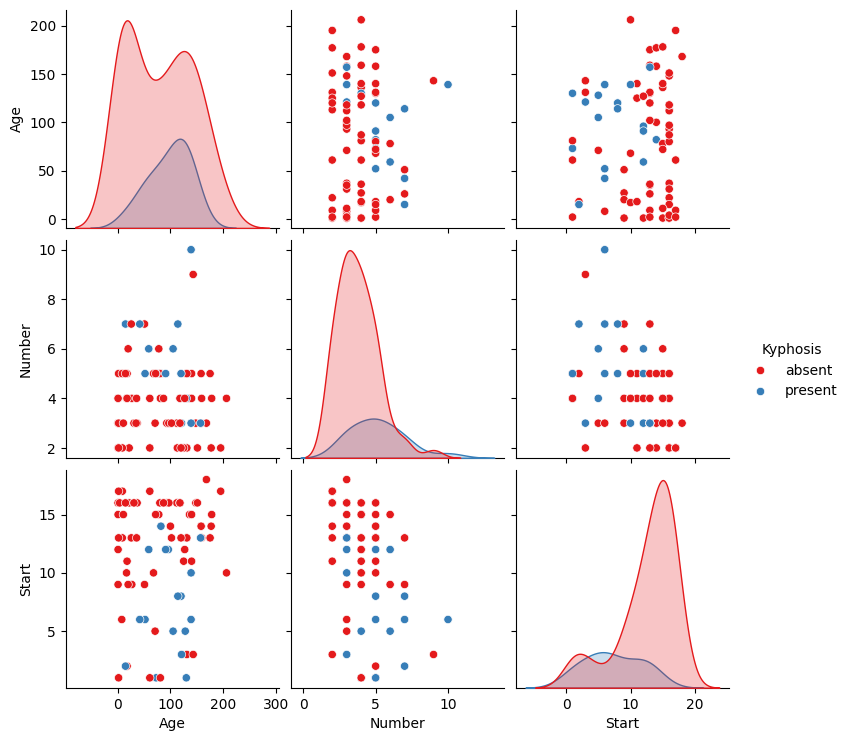

In [22]:
sns.pairplot(df,hue='Kyphosis',palette='Set1')

Interpret the result of the pairplot

The pariplot above shows that a varied distribution in ages, having data points ranging from 100-200. The number, ranging from 0-5, and start, ranging from 10-20, showed a concentrated distribution. The dataset mostly include data points of people with absent kyphosis.

Build the model using Decision Tree

Split the data into training and test set

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X = df.drop('Kyphosis',axis=1)
y = df['Kyphosis']

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30)

Train a single decision tree

In [26]:
from sklearn.tree import DecisionTreeClassifier

In [27]:
dtree = DecisionTreeClassifier()
dtree.fit(X_train,y_train)

DecisionTreeClassifier()

Determine how many nodes are present and what the depth of this (very large) tree is.

The number of nodes and the maximum actual depth.

In [28]:
dtree.tree_.node_count, dtree.tree_.max_depth

(25, 7)

Predict and evaluate the model

In [29]:
predictions = dtree.predict(X_test)

In [30]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score

In [31]:
#evaluate the performance using classification report
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

      absent       0.79      0.83      0.81        18
     present       0.50      0.43      0.46         7

    accuracy                           0.72        25
   macro avg       0.64      0.63      0.64        25
weighted avg       0.71      0.72      0.71        25



Interpret the precision, recall and f1-score

A high precision and f1-score in classifying absent kyphosis and a low precision and f1-score in classifying present kyphosis was seen. Their recalls of 0.77 and 0.67 were also seen and are slightly close with each other. This led to an overall accuracy of 0.76. It has great accuracy, however, it may not perform well in classifying present kyphosis. This is merely due to data imbalance present in the dataset.

In [32]:
#evaluate the performance using confusion matrix
print(confusion_matrix(y_test,predictions))

[[15  3]
 [ 4  3]]


Interpret the performance using classification matrix

The classification matrix presented that the model can greatly classify data points, having 17 true positive predictions and only 5 wrongly predicted points.

In [33]:
#evaluate the performance using accuracy score
print(accuracy_score(y_test, predictions))

0.72


Interpret the performance of the model using accuracy score

The accuracy score infers a slightly great performance for the model prediction.

Create a tree visualization of the model

In [34]:
from IPython.display import Image
from sklearn.tree import export_graphviz
import pydot

features = list(df.columns[1:])
features

['Age', 'Number', 'Start']

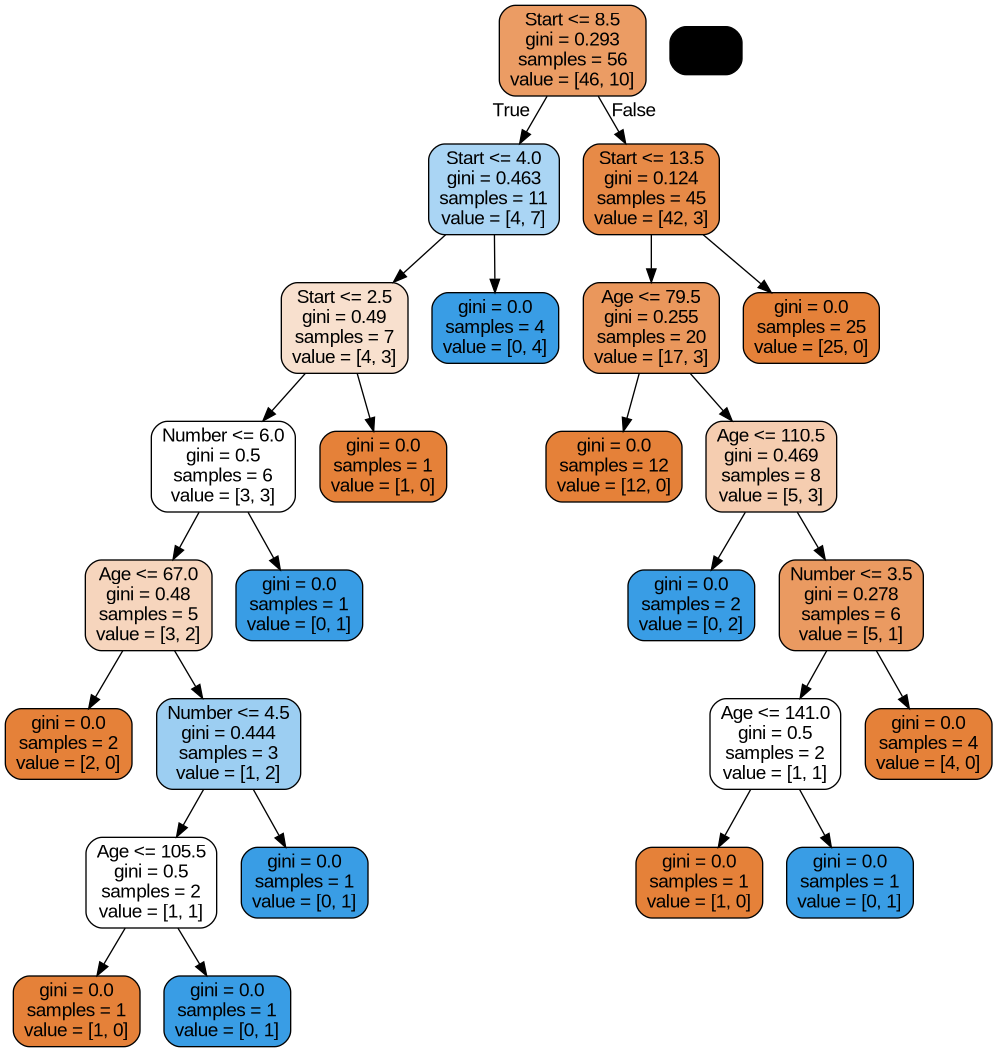

In [35]:
from io import StringIO
from IPython.display import Image, display
import pydotplus

from sklearn.tree import export_graphviz
dot_data = StringIO()

export_graphviz(dtree, out_file=dot_data, feature_names=features,filled=True,rounded=True)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())

    # View the tree image
filename = 'kyphosis .png'
graph.write_png(filename)
img = Image(filename=filename)
display(img)

Supplementary Activity:
* Choose your own dataset
* Import the dataset
* Determine the number of datapoints, columns and data types
* Remove unneccesary columns
* Do data cleaning such as removing empty values(NaN), replacing missing data .
* Perform descriptive statistics such as mean, median and mode
* Perform data visualization
* Build the model using Decision Tree
* Evaluate the model using classification report, accuracy and confusion matrix
* Create a tree visualization of the model

# Supplementary Activity

Dataset: [Penguin Species Dataset](https://www.kaggle.com/datasets/srisyra02/penguin-species-dataset/data)

Importing dataset

In [36]:
# Importing dataset
df = pd.read_csv("penguins.csv")
df.head(5)

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


In [37]:
# Data points
print(f"Data Points: {df.shape[0]}\nColumns: {df.shape[1]}")

Data Points: 1000
Columns: 7


In [38]:
# Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   object 
 1   island             1000 non-null   object 
 2   culmen_length_mm   990 non-null    float64
 3   culmen_depth_mm    990 non-null    float64
 4   flipper_length_mm  990 non-null    float64
 5   body_mass_g        990 non-null    float64
 6   sex                990 non-null    object 
dtypes: float64(4), object(3)
memory usage: 54.8+ KB


In [39]:
# Data types
df.dtypes

,0
species,object
island,object
culmen_length_mm,float64
culmen_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object


In [40]:
# Describe
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,990.000000,990.000000,990.000000,990.000000
mean,43.817778,17.335556,199.224242,4103.311111
std,5.309985,1.779057,13.171660,705.334794
min,32.400000,13.000000,175.000000,2830.000000
25%,39.000000,15.800000,189.000000,3586.000000
50%,43.800000,17.800000,195.000000,3882.000000
75%,48.300000,18.700000,212.000000,4587.000000
max,56.000000,21.400000,235.000000,6317.000000


Data Cleaning

In [41]:
# Create copy
df_clean = df.copy()

# Clean missing rows
df_clean = df.dropna()

df_clean.shape

(951, 7)

In [42]:
# Get numerical columns
dfc_numeric = df_clean.select_dtypes(include='number')

In [43]:
# Mean
dfc_numeric.mean()

,0
culmen_length_mm,43.825026
culmen_depth_mm,17.324711
flipper_length_mm,199.191377
body_mass_g,4096.220820


In [44]:
# Median
dfc_numeric.median()

,0
culmen_length_mm,43.9
culmen_depth_mm,17.8
flipper_length_mm,195.0
body_mass_g,3880.0


In [45]:
# Mode
dfc_numeric.mode()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,38.3,18.2,189.0,3318.0
1,NaN,NaN,NaN,3540.0
2,NaN,NaN,NaN,3710.0
3,NaN,NaN,NaN,3755.0


In [46]:
# Clean df
df_clean.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


Data visualization

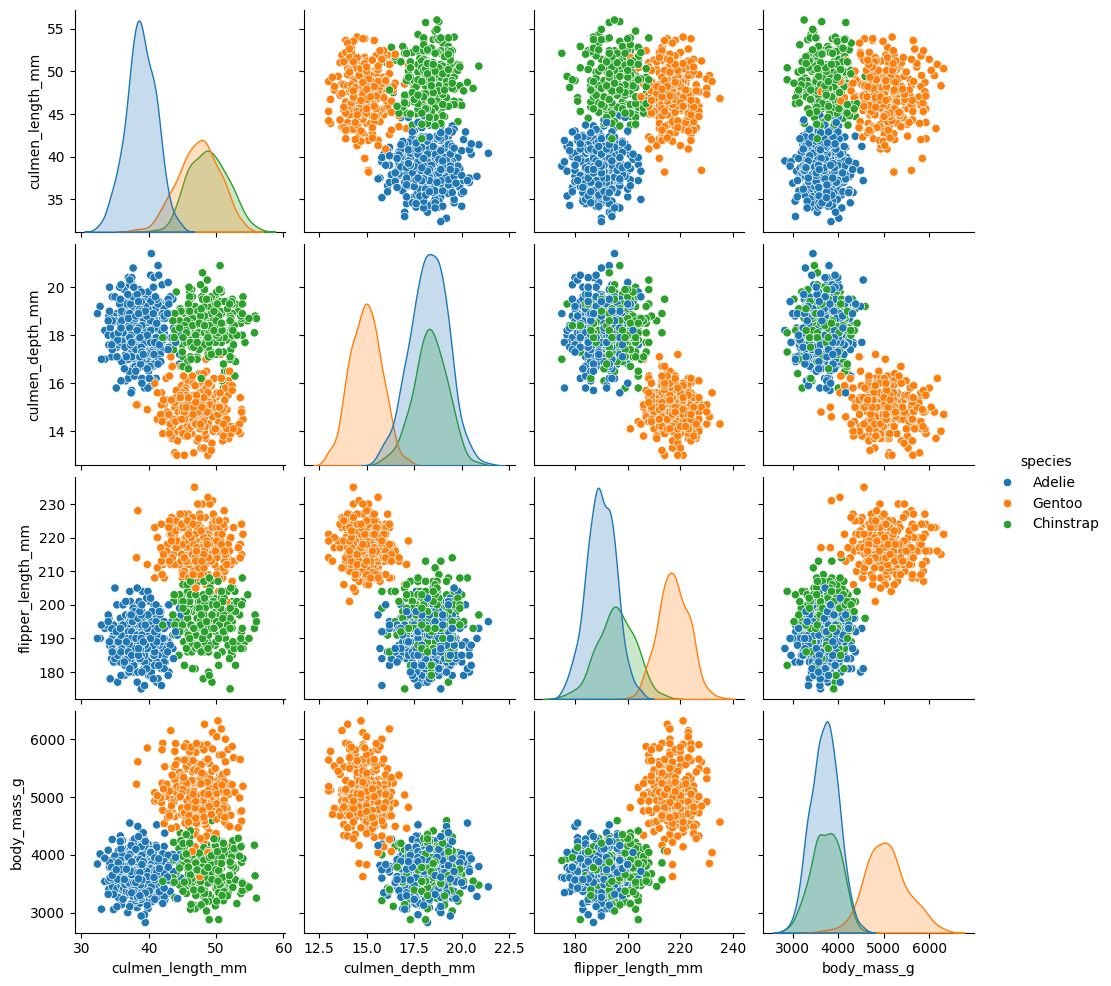

In [47]:
sns.pairplot(data=df_clean, hue="species")
plt.show()

Model Training

In [48]:
X = df_clean.select_dtypes(include="number")
y = df_clean["species"]

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30)

In [50]:
dtree = DecisionTreeClassifier()
dtree.fit(X_train,y_train)

DecisionTreeClassifier()

In [51]:
# Node count, Max depth
dtree.tree_.node_count, dtree.tree_.max_depth

(35, 8)

In [52]:
# Predict
predictions = dtree.predict(X_test)

In [53]:
# Evaluate the performance using classification report
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

      Adelie       0.99      0.98      0.99       140
   Chinstrap       0.86      0.99      0.92        73
      Gentoo       1.00      0.88      0.93        73

    accuracy                           0.95       286
   macro avg       0.95      0.95      0.95       286
weighted avg       0.96      0.95      0.96       286



In [54]:
# Evaluate the performance using confusion matrix
print(confusion_matrix(y_test,predictions))

[[137   3   0]
 [  1  72   0]
 [  0   9  64]]


In [55]:
# Evaluate the performance using accuracy score
print(accuracy_score(y_test, predictions))

0.9545454545454546


In [56]:
# Get features
features = list(X.columns)
features

['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

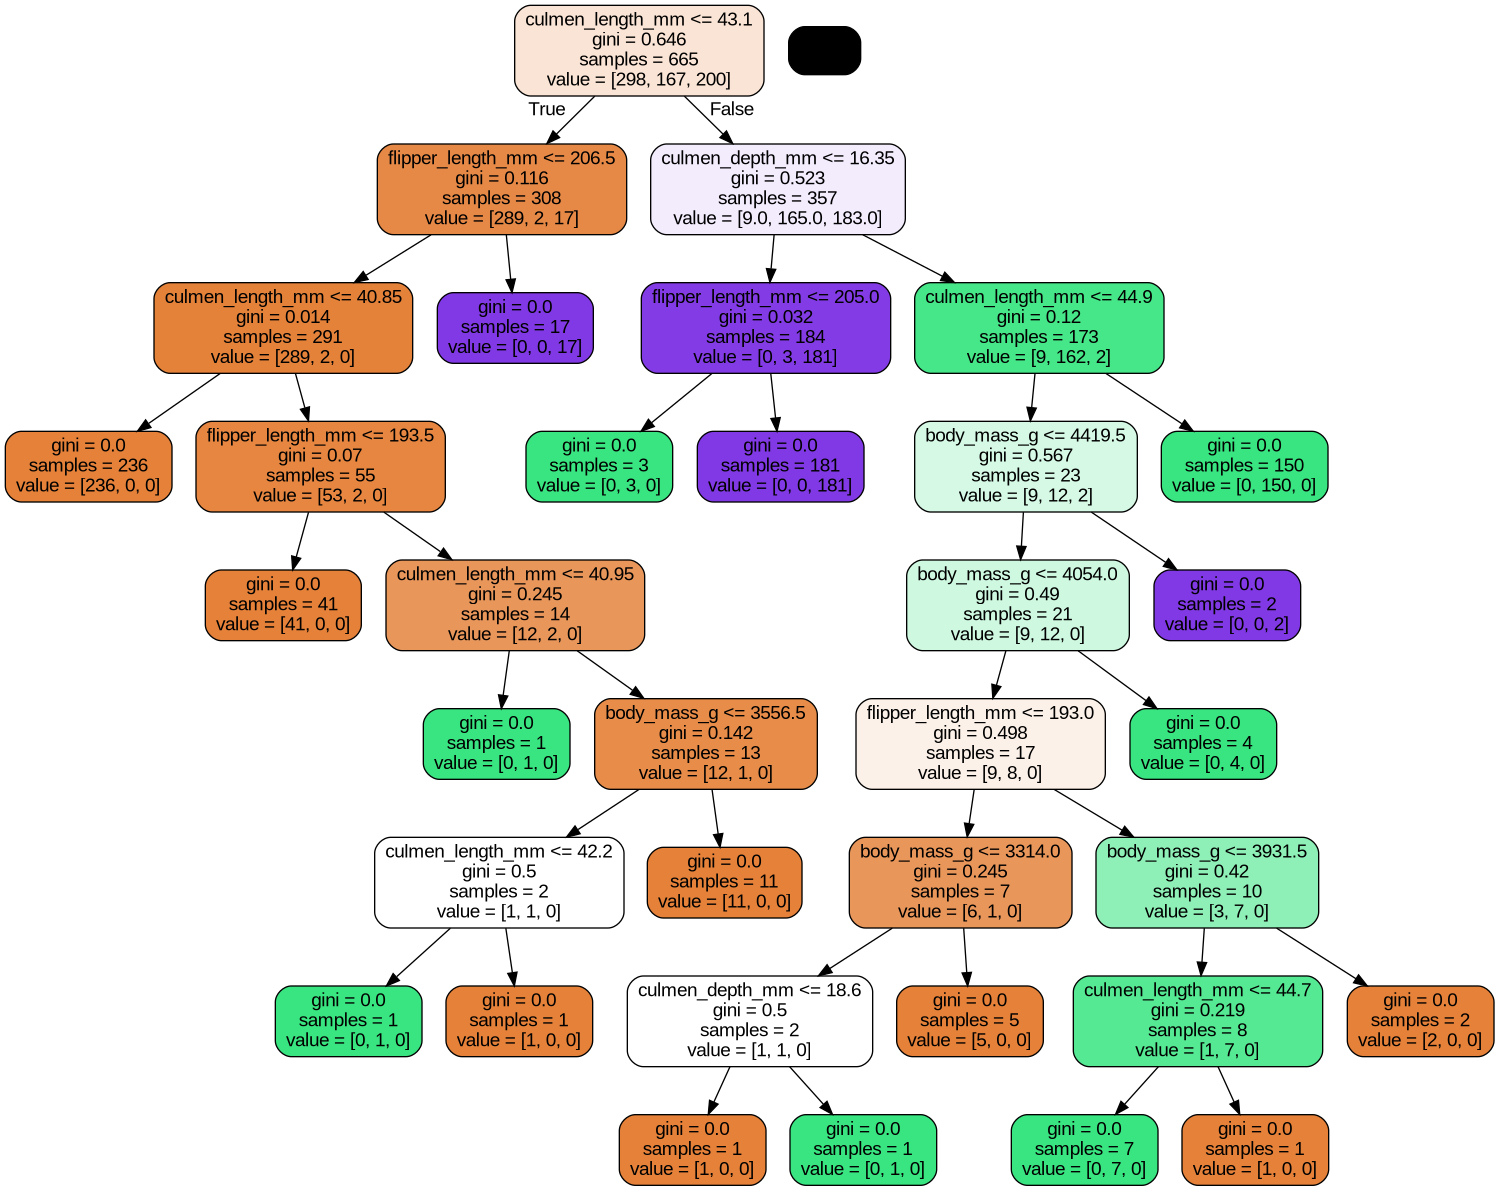

In [57]:
# Create decision tree
dot_data = StringIO()

export_graphviz(dtree, out_file=dot_data, feature_names=features, filled=True, rounded=True)
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())

# View the tree image
filename = 'penguins_decisiontree.png'
graph.write_png(filename)
img = Image(filename=filename)
display(img)

Conclusion

The activity involves the application of the Decision Tree Classifier, which is presented in classifying in absent and present Kyphosis. To do this, the dataset splitted to 70% by 30% is feeded into the decision tree classifier function, which checks for the value of numerical features of each data point. With this, a slightly accurate model was made, with the model accuracy of 72% and the absent Kyphosis being correctly classified more than present Kyphosis. This is mainly due to the data imbalances found in the dataset, where absent Kyphosis data are dominant than present Kyphosis. The decision tree used in the procedure was also printed, showing its max nodes and depth.<br><br>
The same procedure was made in the supplementary activity, but was used for penguin species classification. Applying the decision tree classifier returned a high model accuracy with 95%, having high precision, recall, and f1 score ranging from 86% to 100%. A decision tree was also created to show the workflow made in classifying testing data. The decision tree was also made to check how the classifier model predicts data.